# Avaliação cronológica vs Aleatória na classificação do spam do YouTube

**Pergunta a ser respondida**: classificadores de spam treinados com comentários mais antigos mantém o mesmo desempenho quando são avaliados por comentários mais recentes (publicados depois)?

**Conjunto dos dados**: Alberto, T. & Lochter, J. (2015). *YouTube Spam Collection*. UCI Machine Learning Repository. https://doi.org/10.24432/C58885.

### Como usar esse notebook.
1. Atribua um kernel executável, de preferência Python 3.12.8 ou superior (que foi o qual foi realizado o teste).
2. Instale as bibliotecas na células iniciais. Após, dê Restart e RUN ALL (caso em ambiente VS Code ou JupyterLab). 
3. Os dados vêm do pacote 'ucimlrepo'. Coloque os arquivos 'Youtube0X-*.csv' em uma pasta 'dados/' na mesma pasta em que salvou esse notebook.
4. Os parâmetros do experimento ficam todos na seção 1 abaixo da instalação. Mude eles caso desejar.
5. Os resultados do experimento vão ser salvos após o Run total em uma pasta 'resultados/' na mesma pasta que este arquivo.

### Desenho/resumo do experimento:
1. Variável independente: tipo de divisão (aleatória estratificada × cronológica).
2. Variável dependente: F1 da classe spam (principal), MCC (secundária).
3. Repetições: sorteia-se uma subamostra estratificada de 90% dos comentários. Com isso, as duas divisões mencionadas são aplicadas à mesma subamostra. Assim, serão gerados pares de medidas e variância à cronologia.
4. Teste estatístico: Wilcoxon pareado com correção de Holm entre os classificadores.


## 1. Configuração

Instalação das bibliotecas. Se for sua primeira vez usando, lembre-se de rodar essa célula abaixo, dar restart no kernel e após, Run All.

In [1]:
%pip install -q "pandas>=2.0" scikit-learn scipy matplotlib ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import glob
import os
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC


print("Python ", platform.python_version())
print("pandas ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy ", scipy.__version__)

Python  3.12.8
pandas  2.2.3
scikit-learn 1.7.0
scipy  1.16.0


### Parâmetros

In [3]:
N_REPETICOES = 30
SEMENTES = range(N_REPETICOES)
FRAC_TESTE = 0.20          # igual nas duas divisões
FRAC_SUBAMOSTRA = 0.90
TIRAR_TEXTO_REPETIDO = True
ALFA = 0.05

DIR_DADOS, DIR_SAIDA = "dados", "resultados"
os.makedirs(DIR_SAIDA, exist_ok=True)


def salvar(tabela, arquivo, **kwargs):
    tabela.to_csv(os.path.join(DIR_SAIDA, arquivo), **kwargs)


def salvar_fig(fig, arquivo):
    fig.savefig(os.path.join(DIR_SAIDA, arquivo), bbox_inches="tight")


pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

print(os.getcwd())
print(f"{len(glob.glob(os.path.join(DIR_DADOS, 'Youtube0*.csv')))}/5 CSVs em {DIR_DADOS}/")

c:\Users\Gabriel\Desktop\tudo\Faculdade\Pesquisa Acadêmica
5/5 CSVs em dados/


## 2. Carga dos dados
Por 'ucimlrepo' primeiro, caso não haja conexão, busca por fazer a leitura dos CSVs locais da pasta 'dados/'.
Cada linha deve receber a coluna "VIDEO".

In [4]:
def ler_csvs_locais():
    tabelas = []
    for caminho in sorted(glob.glob(os.path.join(DIR_DADOS, "Youtube0*.csv"))):
        artista = os.path.basename(caminho).split("-", 1)[1].replace(".csv", "")
        tabelas.append(pd.read_csv(caminho).assign(VIDEO=artista))
    return pd.concat(tabelas, ignore_index=True)


try:
    from ucimlrepo import fetch_ucirepo
    bruto = fetch_ucirepo(id=380).data.original.copy()
    origem = "ucimlrepo (id=380)"
except (ImportError, ConnectionError, OSError, ValueError) as e:
    print(f"ucimlrepo falhou ({e}), indo pelos CSVs locais")
    bruto = ler_csvs_locais()
    origem = f"CSVs de {DIR_DADOS}/"

bruto = bruto.rename(columns=lambda c: c.strip().upper())
bruto = bruto.astype({"CLASS": int, "VIDEO": str})

print(f"{len(bruto)} comentários, fonte: {origem}")
bruto.head()

1956 comentários, fonte: ucimlrepo (id=380)


,VIDEO,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS
0,Psy,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1
1,Psy,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1
2,Psy,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1
3,Psy,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1
4,Psy,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1


## 3. Análise exploratória e qualidade dos dados

Converte 'DATE' para data e levanta os problemas de qualidade

In [5]:
dados = bruto.copy()

# Separa o que vem com ou sem data. Datas vazias viram NaN.
sem_data = dados["DATE"].isna() | dados["DATE"].astype(str).str.strip().eq("")
dados["DATA"] = (pd.to_datetime(dados["DATE"], errors="coerce", format="ISO8601", utc=True)
                 .dt.tz_localize(None))
data_invalida = dados["DATA"].isna() & ~sem_data

print(f"sem data: {sem_data.sum()} | data inválida: {data_invalida.sum()}")

sem data: 245 | data inválida: 0


In [6]:
# Tabela 1 do artigo: distribuição por vídeo
por_video = dados.groupby("VIDEO").agg(
    spam=("CLASS", "sum"),
    total=("CLASS", "size"),
    sem_data=("DATA", lambda s: s.isna().sum()),
    primeira_data=("DATA", "min"),
    ultima_data=("DATA", "max"),
)
por_video.insert(1, "legitimos", por_video["total"] - por_video["spam"])
por_video["pct_spam"] = (100 * por_video["spam"] / por_video["total"]).round(1)
for col in ("primeira_data", "ultima_data"):
    por_video[col] = por_video[col].dt.date

linha_total = pd.DataFrame({
    **{col: [por_video[col].sum()] for col in ("spam", "legitimos", "total", "sem_data")},
    "primeira_data": [dados["DATA"].min().date()],
    "ultima_data": [dados["DATA"].max().date()],
    "pct_spam": [round(100 * dados["CLASS"].mean(), 1)],
}, index=["Total"])

tabela1 = pd.concat([por_video, linha_total])
salvar(tabela1, "tabela1_videos.csv")
tabela1

,spam,legitimos,total,sem_data,primeira_data,ultima_data,pct_spam
Eminem,245,203,448,245,2015-05-06,2015-05-29,54.7
Katy Perry,175,175,350,0,2014-07-22,2015-06-05,50.0
LMFAO,236,202,438,0,2014-07-21,2015-05-28,53.9
Psy,175,175,350,0,2013-11-07,2015-06-05,50.0
Shakira,174,196,370,0,2013-07-12,2015-05-29,47.0
Total,1005,951,1956,245,2013-07-12,2015-06-05,51.4


In [7]:
# Duplicatas
id_repetido = dados["COMMENT_ID"].duplicated(keep=False)
texto_repetido = dados["CONTENT"].duplicated(keep=False)

videos_por_texto = dados.groupby("CONTENT")["VIDEO"].nunique()
classes_por_texto = dados.groupby("CONTENT")["CLASS"].nunique()

print(f"Linhas com COMMENT_ID repetido: {int(id_repetido.sum())} | IDs distintos envolvidos: {dados.loc[id_repetido, 'COMMENT_ID'].nunique()}")
print(f"Linhas com texto repetido: {int(texto_repetido.sum())} | textos distintos envolvidos: {dados.loc[texto_repetido, 'CONTENT'].nunique()}")
print(f"Dessas linhas, são spam: {int(dados.loc[texto_repetido, 'CLASS'].sum())}")
print(f"Textos que aparecem em mais de um vídeo: {int((videos_por_texto > 1).sum())}")
print(f"Textos repetidos com rótulos diferentes: {int((classes_por_texto > 1).sum())}")

Linhas com COMMENT_ID repetido: 6 | IDs distintos envolvidos: 3
Linhas com texto repetido: 255 | textos distintos envolvidos: 59
Dessas linhas, são spam: 200
Textos que aparecem em mais de um vídeo: 18
Textos repetidos com rótulos diferentes: 0


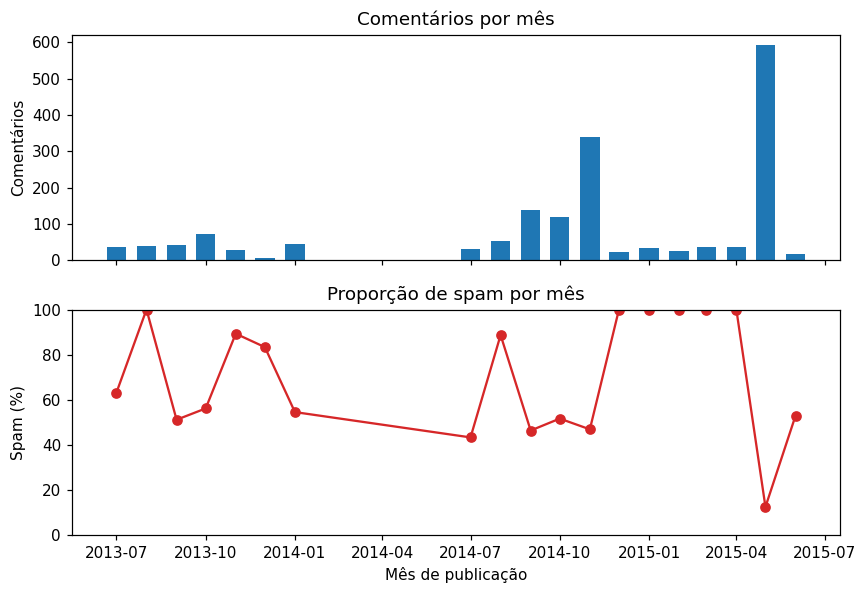

1 mês(es) com menos de 10 comentários, a % de spam desses meses não é confiável


In [8]:
com_data = dados.dropna(subset=["DATA"]).copy()
com_data["MES"] = com_data["DATA"].dt.to_period("M").dt.to_timestamp()
mensal = com_data.groupby("MES")["CLASS"].agg(total="size", spam="mean")

fig, (volume, proporcao) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
volume.bar(mensal.index, mensal["total"], width=20, color="tab:blue")
volume.set(ylabel="Comentários", title="Comentários por mês")
proporcao.plot(mensal.index, 100 * mensal["spam"], marker="o", color="tab:red")
proporcao.set(ylabel="Spam (%)", ylim=(0, 100), title="Proporção de spam por mês",
              xlabel="Mês de publicação")
fig.tight_layout()
salvar_fig(fig, "figura_spam_no_tempo.png")
plt.show()

print(f"{(mensal['total'] < 10).sum()} mês(es) com menos de 10 comentários, "
      "a % de spam desses meses não é confiável")

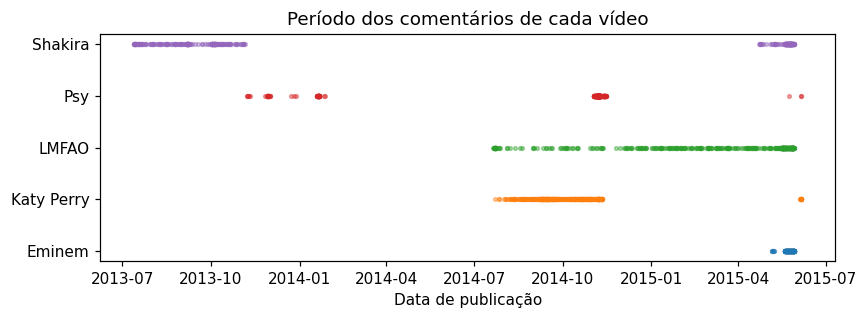

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
for y, (_, grupo) in enumerate(com_data.groupby("VIDEO")):
    ax.scatter(grupo["DATA"], [y] * len(grupo), s=6, alpha=0.4)
artistas = sorted(com_data["VIDEO"].unique())
ax.set_yticks(range(len(artistas)), artistas)
ax.set(xlabel="Data de publicação", title="Período dos comentários de cada vídeo")
fig.tight_layout()
salvar_fig(fig, "figura_periodo_videos.png")
plt.show()

## 4. Pré-processamento
Decisões tomadas para prosseguir:
1. Comentários sem data são removidos pois não tem como ordenar e as duas divisões precisam usar exatamente o mesmo conjunto.
2. IDs repetidos são removidos.
3. Textos repetidos são removidos mantendo apenas o mais antigo, para que o texto não caia no treino e no teste ao mesmo tempo.

In [10]:
def limpar(df, tirar_texto_repetido=True):
    passos = []

    def registra(etapa, d):
        passos.append((etapa, len(d), round(100 * d["CLASS"].mean(), 1)))
        return d

    df = registra("Original", df)
    df = registra("Sem data removidos", df.dropna(subset=["DATA"]))
    df = registra("IDs repetidos removidos", df.sort_values("DATA").drop_duplicates("COMMENT_ID"))
    if tirar_texto_repetido:
        df = registra("Textos repetidos removidos", df.drop_duplicates("CONTENT"))

    df = df.sort_values("DATA").reset_index(drop=True)
    return df, pd.DataFrame(passos, columns=["etapa", "comentarios", "pct_spam"])


limpo, passos_limpeza = limpar(dados, TIRAR_TEXTO_REPETIDO)
salvar(passos_limpeza, "etapas_limpeza.csv", index=False)
passos_limpeza

,etapa,comentarios,pct_spam
0,Original,1956,51.4
1,Sem data removidos,1711,44.4
2,IDs repetidos removidos,1710,44.4
3,Textos repetidos removidos,1559,41.1


## 5. Divisões de treino e teste
1. Aleatória estratificada: sorteio com a mesma proporção de spam no treino e teste.
2. Cronológica global: todos os comentários ordenados por data; 80% mais antigos e 20% mais recentes, teste.
3. Cronológica por vídeo: mesmo corte 80%/20%, mas separado por vídeo. Analisa se a diferença entre o vídeo e o teste global fica concentrado em poucos vídeos.
Em cada repetição, as divisões são aplicadas a mesma subamostra de 90%

In [11]:
def subamostra(df, seed):
    return train_test_split(df, train_size=FRAC_SUBAMOSTRA,
                            stratify=df["CLASS"], random_state=seed)[0]


def split_aleatorio(df, seed):
    return train_test_split(df, test_size=FRAC_TESTE,
                            stratify=df["CLASS"], random_state=seed)


def split_temporal(df, seed=None):
    df = df.sort_values(["DATA", "COMMENT_ID"])  # o ID desempata timestamps iguais
    n_treino = int(round(len(df) * (1 - FRAC_TESTE)))
    return df.iloc[:n_treino], df.iloc[n_treino:]


def split_temporal_por_video(df, seed=None):
    treinos, testes = zip(*(split_temporal(g) for _, g in df.groupby("VIDEO")))
    return pd.concat(treinos), pd.concat(testes)


DIVISOES = {
    "Aleatória": split_aleatorio,
    "Cronológica": split_temporal,
    "Cronológica por vídeo": split_temporal_por_video,
}

## 6. Modelos e métricas
1. Texto representado por TF-IDF. Ajustado no treino.
2. 3 classificadores com parâmetros fixos: Naive Bayes multinomial, Regressão Logística e SVM linear.
3. SPAM é classe positiva. F1 = 2.P.R/(P+R). MCC usa as 4 células da matriz de confusão e não depende da proporção das classes.

In [12]:
def modelos(seed):
    return {
        "Naive Bayes": make_pipeline(TfidfVectorizer(lowercase=True), MultinomialNB()),
        "Regressão Logística": make_pipeline(TfidfVectorizer(lowercase=True),
                                             LogisticRegression(max_iter=1000, random_state=seed)),
        "SVM linear": make_pipeline(TfidfVectorizer(lowercase=True), LinearSVC(random_state=seed)),
    }


def metricas(y, y_hat):
    spam = dict(pos_label=1, zero_division=0)
    return {
        "f1_spam": f1_score(y, y_hat, **spam),
        "mcc": matthews_corrcoef(y, y_hat),
        "precisao": precision_score(y, y_hat, **spam),
        "revocacao": recall_score(y, y_hat, **spam),
        "acuracia_bal": balanced_accuracy_score(y, y_hat),
        "acuracia": accuracy_score(y, y_hat),
    }

## 7. Experimento
Cada execução (semente x divisão x modelo) vira uma linha dentro da tabela resultados.

In [13]:
def rodar(df, cenario):
    registros = []
    for seed in SEMENTES:
        amostra = subamostra(df, seed)
        for divisao, dividir in DIVISOES.items():
            treino, teste = dividir(amostra, seed)
            particao = {
                "n_treino": len(treino),
                "n_teste": len(teste),
                "pct_spam_treino": 100 * treino["CLASS"].mean(),
                "pct_spam_teste": 100 * teste["CLASS"].mean(),
                "inicio_teste": teste["DATA"].min(),
                "fim_teste": teste["DATA"].max(),
            }
            for nome, pipe in modelos(seed).items():
                previsto = pipe.fit(treino["CONTENT"], treino["CLASS"]).predict(teste["CONTENT"])
                registros.append({"cenario": cenario, "semente": seed, "divisao": divisao,
                                  "modelo": nome, **particao,
                                  **metricas(teste["CLASS"], previsto)})
    return pd.DataFrame(registros)


resultados = rodar(limpo, "principal")
salvar(resultados, "resultados_execucoes.csv", index=False)
print(len(resultados), "execuções")
resultados.head()

270 execuções


,cenario,semente,divisao,modelo,n_treino,n_teste,pct_spam_treino,pct_spam_teste,inicio_teste,fim_teste,f1_spam,mcc,precisao,revocacao,acuracia_bal,acuracia
0,principal,0,Aleatória,Naive Bayes,1122,281,41.087344,40.925267,2013-07-13 13:14:30.021,2015-06-05 20:01:23,0.916667,0.869806,0.980198,0.860870,0.924411,0.935943
1,principal,0,Aleatória,Regressão Logística,1122,281,41.087344,40.925267,2013-07-13 13:14:30.021,2015-06-05 20:01:23,0.905660,0.857109,0.989691,0.834783,0.914379,0.928826
2,principal,0,Aleatória,SVM linear,1122,281,41.087344,40.925267,2013-07-13 13:14:30.021,2015-06-05 20:01:23,0.940639,0.905958,0.990385,0.895652,0.944814,0.953737
3,principal,0,Cronológica,Naive Bayes,1122,281,49.286988,8.185053,2015-05-23 02:13:21.735,2015-06-05 20:01:23,0.785714,0.778185,0.666667,0.956522,0.956943,0.957295
4,principal,0,Cronológica,Regressão Logística,1122,281,49.286988,8.185053,2015-05-23 02:13:21.735,2015-06-05 20:01:23,0.800000,0.783629,0.740741,0.869565,0.921217,0.964413


## 8. Resultados

### 8.1 Como ficaram as partições

In [14]:
cols_particao = ["n_treino", "pct_spam_treino", "n_teste", "pct_spam_teste"]
composicao = (resultados.drop_duplicates(["semente", "divisao"])
              .groupby("divisao")[cols_particao]
              .agg(["mean", "std"])
              .round(1))
salvar(composicao, "tabela_composicao_particoes.csv")
composicao

n_treino      pct_spam_treino      n_teste      pct_spam_teste     
                          mean  std            mean  std    mean  std           mean  std
divisao                                                                                  
Aleatória               1122.0  0.0            41.1  0.0   281.0  0.0           40.9  0.0
Cronológica             1122.0  0.0            49.4  0.1   281.0  0.0            7.7  0.6
Cronológica por vídeo   1122.5  0.5            45.1  0.2   280.5  0.5           24.8  0.7

In [15]:
# vídeos presentes no teste, na primeira semente
amostra0 = subamostra(limpo, SEMENTES[0])
for divisao, dividir in DIVISOES.items():
    _, teste0 = dividir(amostra0, SEMENTES[0])
    print(f"{divisao}: {teste0['VIDEO'].value_counts().to_dict()}")

Aleatória: {'Shakira': 74, 'Psy': 63, 'Katy Perry': 59, 'LMFAO': 56, 'Eminem': 29}
Cronológica: {'Eminem': 103, 'Shakira': 81, 'LMFAO': 79, 'Katy Perry': 15, 'Psy': 3}
Cronológica por vídeo: {'Katy Perry': 63, 'Psy': 62, 'LMFAO': 61, 'Shakira': 60, 'Eminem': 34}


### 8.2 desempenho por classificador e divisão

In [16]:
def media_dp(s):
    return f"{s.mean():.3f} ± {s.std():.3f}"


tabela_principal = (resultados
                    .groupby(["modelo", "divisao"])
                    .agg(**{m: (m, media_dp) for m in ("f1_spam", "mcc", "precisao", "revocacao")})
                    .unstack("divisao"))
salvar(tabela_principal, "tabela_principal.csv")
tabela_principal

f1_spam                                                 mcc                                       \
divisao                  Aleatória    Cronológica Cronológica por vídeo      Aleatória    Cronológica Cronológica por vídeo   
modelo                                                                                                                        
Naive Bayes          0.908 ± 0.022  0.692 ± 0.040         0.908 ± 0.010  0.854 ± 0.033  0.685 ± 0.038         0.878 ± 0.014   
Regressão Logística  0.915 ± 0.018  0.743 ± 0.027         0.911 ± 0.010  0.864 ± 0.028  0.725 ± 0.027         0.882 ± 0.014   
SVM linear           0.940 ± 0.013  0.765 ± 0.035         0.916 ± 0.013  0.900 ± 0.021  0.747 ± 0.036         0.889 ± 0.017   

                          precisao                                           revocacao                                       
divisao                  Aleatória    Cronológica Cronológica por vídeo      Aleatória    Cronológica Cronológica por vídeo  
modelo                                                                                                                       
Naive Bayes          0.963 ± 0.016  0.557 ± 0.048         0.903 ± 0.016  0.859 ± 0.035  0.917 ± 0.030         0.914 ± 0.014  
Regressão Logística  0.963 ± 0.018  0.666 ± 0.041         0.908 ± 0.013  0.872 ± 0.029  0.840 ± 0.024         0.915 ± 0.014  
SVM linear           0.955 ± 0.016  0.719 ± 0.050         0.904 ± 0.018  0.925 ± 0.022  0.820 ± 0.032         0.930 ± 0.013

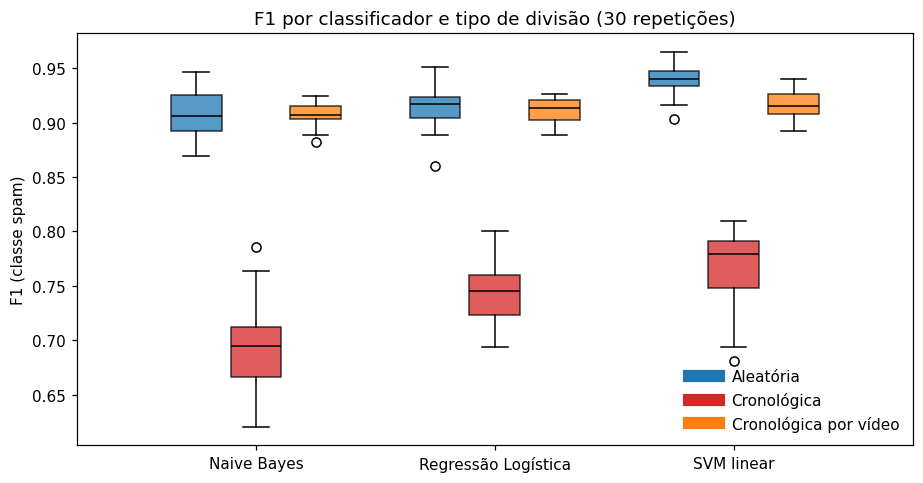

In [17]:
# Figura principal: distribuição do F1 (spam) nas repetições
nomes_div = list(DIVISOES)
nomes_modelo = list(modelos(0))
cor = dict(zip(nomes_div, ["tab:blue", "tab:red", "tab:orange"]))
LARG = 0.25
x = np.arange(len(nomes_modelo))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for j, div in enumerate(nomes_div):
    da_divisao = resultados[resultados["divisao"] == div]
    caixas = ax.boxplot([da_divisao.loc[da_divisao["modelo"] == m, "f1_spam"] for m in nomes_modelo],
                        positions=x + (j - 1) * LARG, widths=LARG * 0.85,
                        patch_artist=True, showfliers=True,
                        medianprops={"color": "black"})
    for caixa in caixas["boxes"]:
        caixa.set_facecolor(cor[div])
        caixa.set_alpha(0.75)
    ax.plot([], [], color=cor[div], linewidth=8, label=div)

ax.set_xticks(x, nomes_modelo)
ax.set(ylabel="F1 (classe spam)",
       title=f"F1 por classificador e tipo de divisão ({len(SEMENTES)} repetições)")
ax.legend(frameon=False)
fig.tight_layout()
salvar_fig(fig, "figura_principal_f1.png")
plt.show()

### 8.3 Comparação estatística
Para cada classificador, compara a métrica de divisão cronológica com a aleatória na mesma semente. Teste de Wilcoxon pareado, bilateral, com correção de Holm.
dif_media e dif_mediana: diferença de (cronológica - aleatória). Se negativo, cronológica é pior.
r_rank_biserial: tamanho do efeito, de -1 a 1.



In [18]:
def holm(pvals):
    # Ajuste sequencial 
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    ordem = np.argsort(p)

    ajustado = np.minimum(1.0, np.maximum.accumulate((m - np.arange(m)) * p[ordem]))
    saida = np.empty_like(p)
    saida[ordem] = ajustado
    return saida


def rank_biserial(dif):
    # Tamanho de efeito para Wilcoxon pareado: r = (W+ - W-)/(W+ + W-)
    dif = dif[dif != 0]
    if len(dif) == 0:
        return 0.0
    postos = stats.rankdata(np.abs(dif))
    w_mais, w_menos = postos[dif > 0].sum(), postos[dif < 0].sum()
    return (w_mais - w_menos) / (w_mais + w_menos)


def comparar(res, metrica, div_a="Cronológica", div_b="Aleatória"):
    def por_semente(modelo, divisao):
        return res.query("modelo == @modelo and divisao == @divisao").set_index("semente")[metrica]

    linhas = []
    for modelo in res["modelo"].unique():
        a, b = por_semente(modelo, div_a), por_semente(modelo, div_b)
        dif = (a - b.loc[a.index]).to_numpy()
        # wilcoxon quebra quando todas as diferenças são zero
        p = 1.0 if np.all(dif == 0) else stats.wilcoxon(dif, alternative="two-sided").pvalue
        linhas.append({
            "modelo": modelo,
            "comparacao": f"{div_a} - {div_b}",
            "metrica": metrica,
            "dif_media": dif.mean(),
            "dif_mediana": np.median(dif),
            "r_rank_biserial": rank_biserial(dif),
            "p_valor": p,
        })

    tabela = pd.DataFrame(linhas)
    tabela["p_holm"] = holm(tabela["p_valor"])
    tabela["significativo"] = tabela["p_holm"] < ALFA
    return tabela


testes = pd.concat([comparar(resultados, metrica, div_a=div)
                    for div in ("Cronológica", "Cronológica por vídeo")
                    for metrica in ("f1_spam", "mcc")],
                   ignore_index=True)
salvar(testes, "tabela_testes_estatisticos.csv", index=False)
testes.round(4)

,modelo,comparacao,metrica,dif_media,dif_mediana,r_rank_biserial,p_valor,p_holm,significativo
0,Naive Bayes,Cronológica - Aleatória,f1_spam,-0.2160,-0.2238,-1.0000,0.0000,0.0000,True
1,Regressão Logística,Cronológica - Aleatória,f1_spam,-0.1723,-0.1723,-1.0000,0.0000,0.0000,True
2,SVM linear,Cronológica - Aleatória,f1_spam,-0.1743,-0.1648,-1.0000,0.0000,0.0000,True
3,Naive Bayes,Cronológica - Aleatória,mcc,-0.1689,-0.1715,-1.0000,0.0000,0.0000,True
4,Regressão Logística,Cronológica - Aleatória,mcc,-0.1394,-0.1433,-1.0000,0.0000,0.0000,True
5,SVM linear,Cronológica - Aleatória,mcc,-0.1527,-0.1405,-1.0000,0.0000,0.0000,True
6,Naive Bayes,Cronológica por vídeo - Aleatória,f1_spam,0.0007,0.0101,0.0366,0.8712,0.8712,False
7,Regressão Logística,Cronológica por vídeo - Aleatória,f1_spam,-0.0035,-0.0039,-0.2690,0.2059,0.4118,False
8,SVM linear,Cronológica por vídeo - Aleatória,f1_spam,-0.0231,-0.0243,-0.9226,0.0000,0.0000,True
9,Naive Bayes,Cronológica por vídeo - Aleatória,mcc,0.0240,0.0356,0.6301,0.0019,0.0037,True


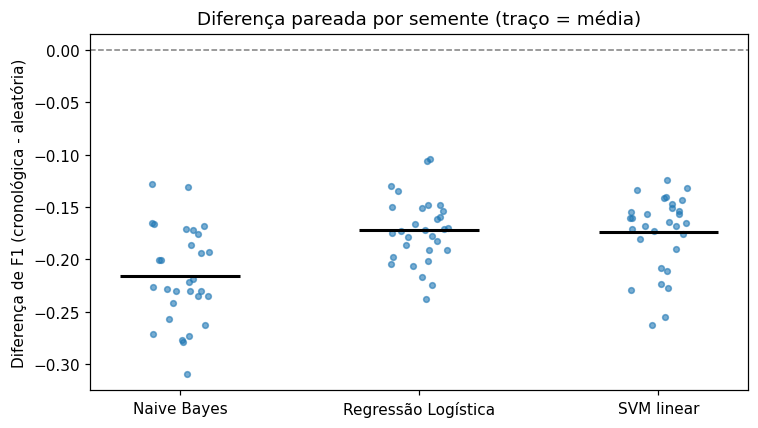

In [19]:
# Figura: diferenças pareadas (cronológica - aleatória) por semente
fig, ax = plt.subplots(figsize=(7, 4))
jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(SEMENTES))  # mesmo jitter nos 3 modelos
for i, modelo in enumerate(nomes_modelo):
    f1 = resultados[resultados["modelo"] == modelo].pivot(index="semente", columns="divisao",
                                                          values="f1_spam")
    dif = f1["Cronológica"] - f1["Aleatória"]
    ax.scatter(i + jitter, dif, s=14, alpha=0.6, color="tab:blue")
    ax.hlines(dif.mean(), i - 0.25, i + 0.25, color="black", linewidth=2)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(len(nomes_modelo)), nomes_modelo)
ax.set(ylabel="Diferença de F1 (cronológica - aleatória)",
       title="Diferença pareada por semente (traço = média)")
fig.tight_layout()
salvar_fig(fig, "figura_diferencas_pareadas.png")
plt.show()

## 9. Análise de controle sobre o efeito dos textos repetidos
Repete o experimento sem remover os textos repetidos.

In [20]:
com_repetidos, _ = limpar(dados, tirar_texto_repetido=False)
resultados_controle = rodar(com_repetidos, "com textos repetidos")
salvar(resultados_controle, "resultados_controle.csv", index=False)

tabela_controle = (pd.concat([resultados, resultados_controle])
                   .loc[lambda d: d["divisao"].isin(["Aleatória", "Cronológica"])]
                   .groupby(["modelo", "divisao", "cenario"])["f1_spam"]
                   .agg(media_dp)
                   .unstack("cenario"))
salvar(tabela_controle, "tabela_controle_repetidos.csv")
print(f"comentários com repetidos: {len(com_repetidos)} | sem: {len(limpo)}")
tabela_controle

comentários com repetidos: 1710 | sem: 1559


cenario                         com textos repetidos      principal
modelo              divisao                                        
Naive Bayes         Aleatória          0.933 ± 0.014  0.908 ± 0.022
                    Cronológica        0.592 ± 0.025  0.692 ± 0.040
Regressão Logística Aleatória          0.932 ± 0.020  0.915 ± 0.018
                    Cronológica        0.785 ± 0.028  0.743 ± 0.027
SVM linear          Aleatória          0.952 ± 0.012  0.940 ± 0.013
                    Cronológica        0.807 ± 0.029  0.765 ± 0.035

## 10. Conferência da reprodutibilidade
Para verificar se os números não mudam

In [21]:
assinatura = resultados[["f1_spam", "mcc"]].sum().round(6).to_dict()
print("assinatura:", assinatura)
print(f"\n{DIR_SAIDA}/", *sorted(os.listdir(DIR_SAIDA)), sep="\n  ")

assinatura: {'f1_spam': 230.931763, 'mcc': 222.672127}

resultados/
  etapas_limpeza.csv
  figura_diferencas_pareadas.png
  figura_periodo_videos.png
  figura_principal_f1.png
  figura_spam_no_tempo.png
  resultados_controle.csv
  resultados_execucoes.csv
  tabela1_videos.csv
  tabela_composicao_particoes.csv
  tabela_controle_repetidos.csv
  tabela_principal.csv
  tabela_testes_estatisticos.csv
